# Comprehensive Exploratory Data Analysis (EDA) of AUV Telemetry
## Platform: Autosub6000 Autonomous Underwater Vehicle (AURORA Mission M86)
**Robotics Semester 5 Project — Phase 1 Modeling Pipeline**  
*Implemented using pure **Pandas** and **Matplotlib***

---

### Notebook Overview & Objectives
This notebook carries out a complete, end-to-end Exploratory Data Analysis (EDA) of continuous high-rate telemetry logged by the Autosub6000 AUV during deep-sea ocean survey Mission M86.
Every stage is designed to answer fundamental robotics and modeling questions:
1. **Data Ingestion & Hygiene:** What is the sample volume, structure, and physical validity of the dataset?
2. **Missing Values & Sampling Regularity:** Are timestamps continuous and uniformly spaced at 0.50 Hz ($\Delta t = 2.0\text{ s}$)?
3. **Statistical State Profiling:** What are the central tendencies, dispersion, skewness, and extreme values across all 7 state variables?
4. **Univariate Distributions:** How are vehicle speed, operating depth, pitch, roll, and heading distributed?
5. **Outlier Envelopes:** Where do extreme sensor readings occur and what are their physical causes?
6. **Bivariate & Hydrodynamic Couplings:** How do surge speed, pitch, depth rate, and heading correlate?
7. **Spatial Trajectory & Bathymetry:** What is the 2D lawnmower survey path and 3D dive profile?
8. **Underwater Acoustic Sensor Noise:** How do USBL acoustic positioning transceiver jumps impact navigation measurements?
9. **Zero-Leakage Splitting:** How is the data chronologically partitioned to prevent future data leakage?


In [1]:
# 1. Imports and Global Plot Configurations
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Configure Matplotlib styling (clean, publication quality)
plt.style.use('default')
plt.rcParams.update({
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.family': 'sans-serif',
    'font.size': 10.5,
    'axes.labelsize': 11.5,
    'axes.titlesize': 12.5,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'figure.titlesize': 14.5,
    'figure.titleweight': 'bold',
    'grid.alpha': 0.5,
    'grid.linestyle': '--'
})

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")


Libraries imported successfully!
Pandas version: 3.0.3


---
## 1. Data Ingestion & Structural Inspection
We load the chronological splits (`train.csv`, `val.csv`, `test.csv`) from `data/processed/` using Pandas with `low_memory=False` to ensure optimal type inference.


In [2]:
# Resolve project directory structure
base_dir = os.path.dirname(os.path.abspath('__file__'))
if not os.path.exists(os.path.join(base_dir, "data", "processed")):
    # If running from repo root
    processed_dir = os.path.join(base_dir, "presentationphase1", "data", "processed")
else:
    processed_dir = os.path.join(base_dir, "data", "processed")

print(f"Loading data from: {processed_dir}")

train_df = pd.read_csv(os.path.join(processed_dir, "train.csv"), low_memory=False)
val_df = pd.read_csv(os.path.join(processed_dir, "val.csv"), low_memory=False)
test_df = pd.read_csv(os.path.join(processed_dir, "test.csv"), low_memory=False)

# Combine for holistic exploratory data analysis
full_df = pd.concat([train_df, val_df, test_df], ignore_index=True)

print(f"Total Combined Telemetry Samples: {len(full_df):,}")
print(f"  * Train Set:      {len(train_df):,} rows ({len(train_df)/len(full_df)*100:.1f}%)")
print(f"  * Validation Set: {len(val_df):,} rows ({len(val_df)/len(full_df)*100:.1f}%)")
print(f"  * Test Set:       {len(test_df):,} rows ({len(test_df)/len(full_df)*100:.1f}%)")
print(f"Total Columns Logged: {len(full_df.columns)}")


Loading data from: C:\Users\eswar\OneDrive\Dokumen\RoboticsSEM5\presentationphase1\data\processed
Total Combined Telemetry Samples: 31,944
  * Train Set:      22,360 rows (70.0%)
  * Validation Set: 4,792 rows (15.0%)
  * Test Set:       4,792 rows (15.0%)
Total Columns Logged: 142


In [3]:
# Define the 7 Primary Robotics State Variables
core_vars = {
    'North': 'North Position (m)',
    'East': 'East Position (m)',
    'depth': 'Depth Below Surface (m)',
    'Roll': 'Roll Angle (rad)',
    'Pitch': 'Pitch Angle (rad)',
    'Heading': 'Heading Angle (rad)',
    'GroundSpeed': 'Surge Speed over Ground (m/s)'
}

# Inspect DataFrame info and memory usage
df_core = full_df[list(core_vars.keys())].copy()
df_core.columns = [core_vars[c] for c in df_core.columns]
print(df_core.info())


<class 'pandas.DataFrame'>
RangeIndex: 31944 entries, 0 to 31943
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   North Position (m)             31944 non-null  float64
 1   East Position (m)              31944 non-null  float64
 2   Depth Below Surface (m)        31944 non-null  float64
 3   Roll Angle (rad)               31944 non-null  float64
 4   Pitch Angle (rad)              31944 non-null  float64
 5   Heading Angle (rad)            31944 non-null  float64
 6   Surge Speed over Ground (m/s)  31944 non-null  float64
dtypes: float64(7)
memory usage: 1.7 MB
None


---
## 2. Data Quality, Hygiene & Sampling Continuity Audit
Reliable physical and machine learning dynamic models require verified sensor integrity:
- Zero NaN (missing) entries in key states
- Absence of infinite or corrupt values
- Uniform temporal sampling interval (nominal $\Delta t = 2.0\text{ s}$ / 0.50 Hz)


In [4]:
# 1. Missing Value and Infinite Value Audit
missing_counts = full_df[list(core_vars.keys())].isnull().sum()
infinite_counts = np.isinf(full_df[list(core_vars.keys())].select_dtypes(include=[np.number])).sum()

audit_df = pd.DataFrame({
    'State Variable': [core_vars[c] for c in core_vars.keys()],
    'Missing Count (NaN)': missing_counts.values,
    'Missing (%)': (missing_counts.values / len(full_df)) * 100,
    'Infinite Count (Inf)': infinite_counts.values
})
print("=== SENSOR DATA INTEGRITY AUDIT ===")
display(audit_df)


=== SENSOR DATA INTEGRITY AUDIT ===
                  State Variable  Missing Count (NaN)  Missing (%)  Infinite Count (Inf)
0             North Position (m)                    0          0.0                     0
1              East Position (m)                    0          0.0                     0
2        Depth Below Surface (m)                    0          0.0                     0
3               Roll Angle (rad)                    0          0.0                     0
4              Pitch Angle (rad)                    0          0.0                     0
5            Heading Angle (rad)                    0          0.0                     0
6  Surge Speed over Ground (m/s)                    0          0.0                     0


=== SAMPLING INTERVAL (Delta t) STATISTICAL SUMMARY ===
count    31943.000000
mean         2.020787
std          1.993809
min          2.000000
25%          2.000000
50%          2.000000
75%          2.000000
max        268.000000
Name: Seconds, dtype: float64


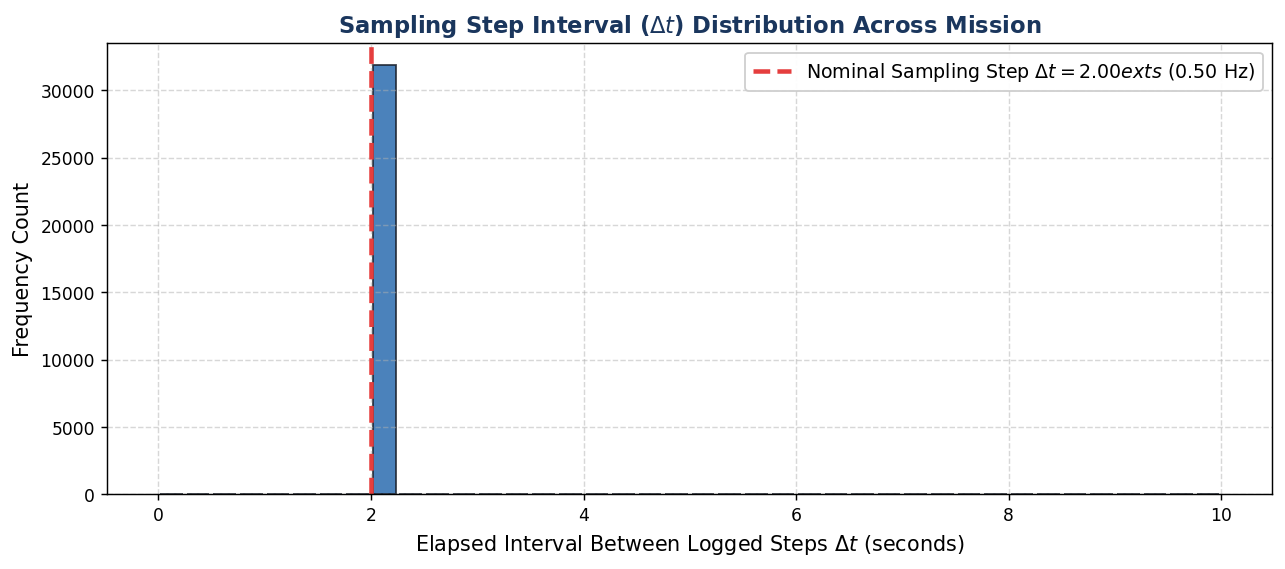

In [5]:
# 2. Sampling Interval (Delta t) Regularity
if 'Seconds' in full_df.columns:
    dt_series = full_df['Seconds'].diff().dropna()
    dt_stats = dt_series.describe()
    print("=== SAMPLING INTERVAL (Delta t) STATISTICAL SUMMARY ===")
    print(dt_stats)

    # Plot Sampling Interval Distribution
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.hist(dt_series, bins=40, range=[0, 10], color='#2B6CB0', edgecolor='#1A202C', alpha=0.85, rwidth=0.85)
    ax.axvline(2.0, color='#E53E3E', linestyle='--', lw=2.5, label=r"Nominal Sampling Step $\Delta t = 2.00	ext{ s}$ (0.50 Hz)")
    ax.set_title(r"Sampling Step Interval ($\Delta t$) Distribution Across Mission", color='#1A365D')
    ax.set_xlabel(r"Elapsed Interval Between Logged Steps $\Delta t$ (seconds)")
    ax.set_ylabel("Frequency Count")
    ax.grid(True)
    ax.legend(loc='upper right', framealpha=0.95)
    plt.tight_layout()
    plt.show()


---
## 3. Comprehensive Descriptive Statistical Profiling
We calculate all statistical moments:
- **Central Tendency:** Mean, Median (50th percentile)
- **Dispersion:** Standard Deviation, Interquartile Range (IQR = Q75 - Q25), Variance
- **Extremes:** Minimum, Maximum
- **Shape Characteristics:** Skewness (asymmetry), Kurtosis (peakedness / heavy tails)
- **Outlier Count:** Number of values outside the standard Tukey fence $[Q25 - 1.5\times\text{IQR}, Q75 + 1.5\times\text{IQR}]$


In [6]:
stats_records = []
for col, label in core_vars.items():
    s = full_df[col].dropna()
    q25 = float(s.quantile(0.25))
    q50 = float(s.median())
    q75 = float(s.quantile(0.75))
    iqr = q75 - q25
    outliers = int(((s < (q25 - 1.5 * iqr)) | (s > (q75 + 1.5 * iqr))).sum())
    
    stats_records.append({
        'State Variable': label,
        'Mean': float(s.mean()),
        'Std Dev': float(s.std()),
        'Min': float(s.min()),
        '25% (Q1)': q25,
        'Median': q50,
        '75% (Q3)': q75,
        'Max': float(s.max()),
        'IQR': float(iqr),
        'Skewness': float(s.skew()),
        'Kurtosis': float(s.kurtosis()),
        'Outlier Count': outliers,
        'Outlier (%)': float(outliers / len(s) * 100)
    })

stats_df = pd.DataFrame(stats_records)
print("=== TELEMETRY SUMMARY DESCRIPTIVE STATISTICS ===")
display(stats_df.round(4))


=== TELEMETRY SUMMARY DESCRIPTIVE STATISTICS ===
                  State Variable       Mean    Std Dev       Min  25% (Q1)     Median   75% (Q3)        Max        IQR  Skewness  Kurtosis  Outlier Count  Outlier (%)
0             North Position (m)  2387.1081  1646.6779 -336.3647  901.0125  2454.2944  4038.1550  4632.3806  3137.1425   -0.1349   -1.3727              0       0.0000
1              East Position (m)   595.9526   241.1862 -124.5771  354.6296   618.6287   851.0047  1034.7133   496.3751    0.0399   -1.3095              0       0.0000
2        Depth Below Surface (m)    68.3395    34.4973    0.0009   56.9912    60.3414    93.9212   108.3848    36.9300   -0.8128   -0.3989           4685      14.6663
3               Roll Angle (rad)     0.2294     0.0471   -0.2488    0.2199     0.2232     0.2269     1.5047     0.0070   13.0032  255.6328           4234      13.2544
4              Pitch Angle (rad)    -0.0122     0.0518   -0.6589   -0.0194    -0.0113    -0.0032     0.7054     0.01

---
## 4. Univariate State Distributions & Histograms
Here we examine the distribution shapes for:
1. **Surge Speed ($U$):** Centered near $1.19\text{ m/s}$, confirming the AUV's steady cruising governor mode.
2. **Operating Depth ($z$):** Multimodal, showing survey lawnmower tracks at $60\text{ m}$ and $94\text{ m}$.
3. **Heading ($\psi$):** Concentrated along reciprocating transect tracks (approximately North $\sim 0\text{ rad}$ and South $\sim \pi\text{ rad}$).
4. **Pitch ($\theta$):** Centered near zero ($-0.012\text{ rad}$), with excursions during diving/climbing transitions.
5. **Roll ($\phi$):** Unimodal around $+0.23\text{ rad}$, caused by hydrodynamic propeller torque trim.


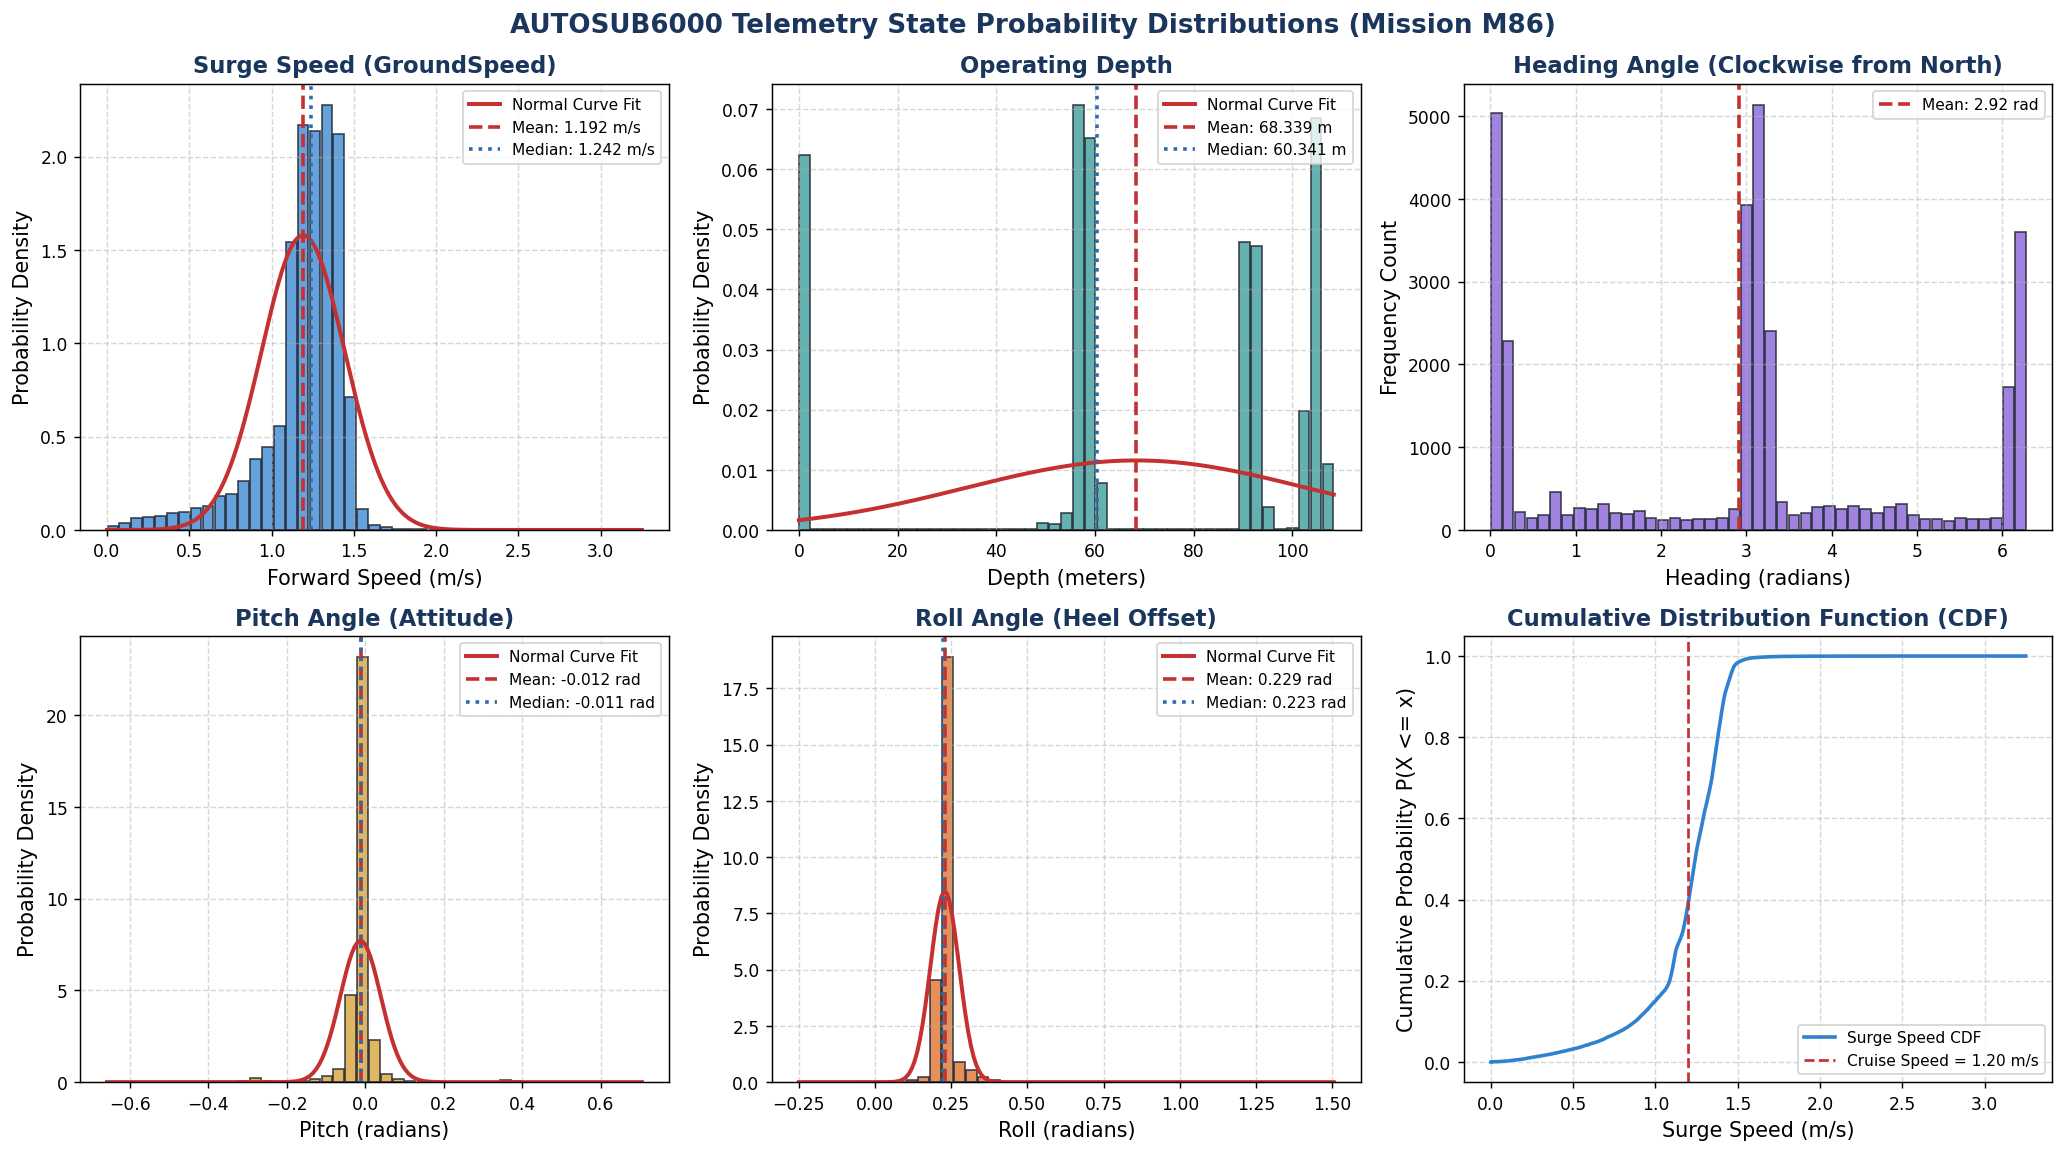

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("AUTOSUB6000 Telemetry State Probability Distributions (Mission M86)", color='#1A365D', y=0.98)

def plot_histogram_with_pdf(ax, series, title, xlabel, color, unit=''):
    counts, bin_edges, _ = ax.hist(series, bins=45, density=True, color=color, edgecolor='#1A202C', alpha=0.75, rwidth=0.9)
    mu, sigma = series.mean(), series.std()
    if sigma > 0:
        x_grid = np.linspace(bin_edges[0], bin_edges[-1], 200)
        pdf = (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_grid - mu) / sigma) ** 2)
        ax.plot(x_grid, pdf, color='#C53030', lw=2.2, label='Normal Curve Fit')
    ax.axvline(mu, color='#C53030', linestyle='--', lw=2.0, label=f"Mean: {mu:.3f} {unit}".strip())
    ax.axvline(series.median(), color='#2B6CB0', linestyle=':', lw=2.0, label=f"Median: {series.median():.3f} {unit}".strip())
    ax.set_title(title, color='#1A365D')
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability Density")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8.5)

plot_histogram_with_pdf(axes[0, 0], full_df['GroundSpeed'], "Surge Speed (GroundSpeed)", "Forward Speed (m/s)", '#3182CE', 'm/s')
plot_histogram_with_pdf(axes[0, 1], full_df['depth'], "Operating Depth", "Depth (meters)", '#319795', 'm')

# Heading
axes[0, 2].hist(full_df['Heading'], bins=45, color='#805AD5', edgecolor='#1A202C', alpha=0.75, rwidth=0.9)
axes[0, 2].axvline(full_df['Heading'].mean(), color='#C53030', linestyle='--', lw=2.0, label=f"Mean: {full_df['Heading'].mean():.2f} rad")
axes[0, 2].set_title("Heading Angle (Clockwise from North)", color='#1A365D')
axes[0, 2].set_xlabel("Heading (radians)")
axes[0, 2].set_ylabel("Frequency Count")
axes[0, 2].grid(True)
axes[0, 2].legend(loc='upper right', fontsize=8.5)

plot_histogram_with_pdf(axes[1, 0], full_df['Pitch'], "Pitch Angle (Attitude)", "Pitch (radians)", '#D69E2E', 'rad')
plot_histogram_with_pdf(axes[1, 1], full_df['Roll'], "Roll Angle (Heel Offset)", "Roll (radians)", '#DD6B20', 'rad')

# Cumulative Distribution Function (CDF) of Surge Speed and Depth
speed_sorted = np.sort(full_df['GroundSpeed'])
depth_sorted = np.sort(full_df['depth'])
p_cdf = np.linspace(0, 1, len(speed_sorted))

ax_cdf = axes[1, 2]
ax_cdf.plot(speed_sorted, p_cdf, color='#3182CE', lw=2.0, label='Surge Speed CDF')
ax_cdf.set_title("Cumulative Distribution Function (CDF)", color='#1A365D')
ax_cdf.set_xlabel("Surge Speed (m/s)")
ax_cdf.set_ylabel("Cumulative Probability P(X <= x)")
ax_cdf.axvline(1.20, color='#C53030', linestyle='--', label="Cruise Speed = 1.20 m/s")
ax_cdf.grid(True)
ax_cdf.legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.show()


---
## 5. Outlier Analysis & Dispersion Envelopes (Box Plots)
Box plots allow visualizing the medians, interquartile ranges, and potential outlier fliers for all operational variables.


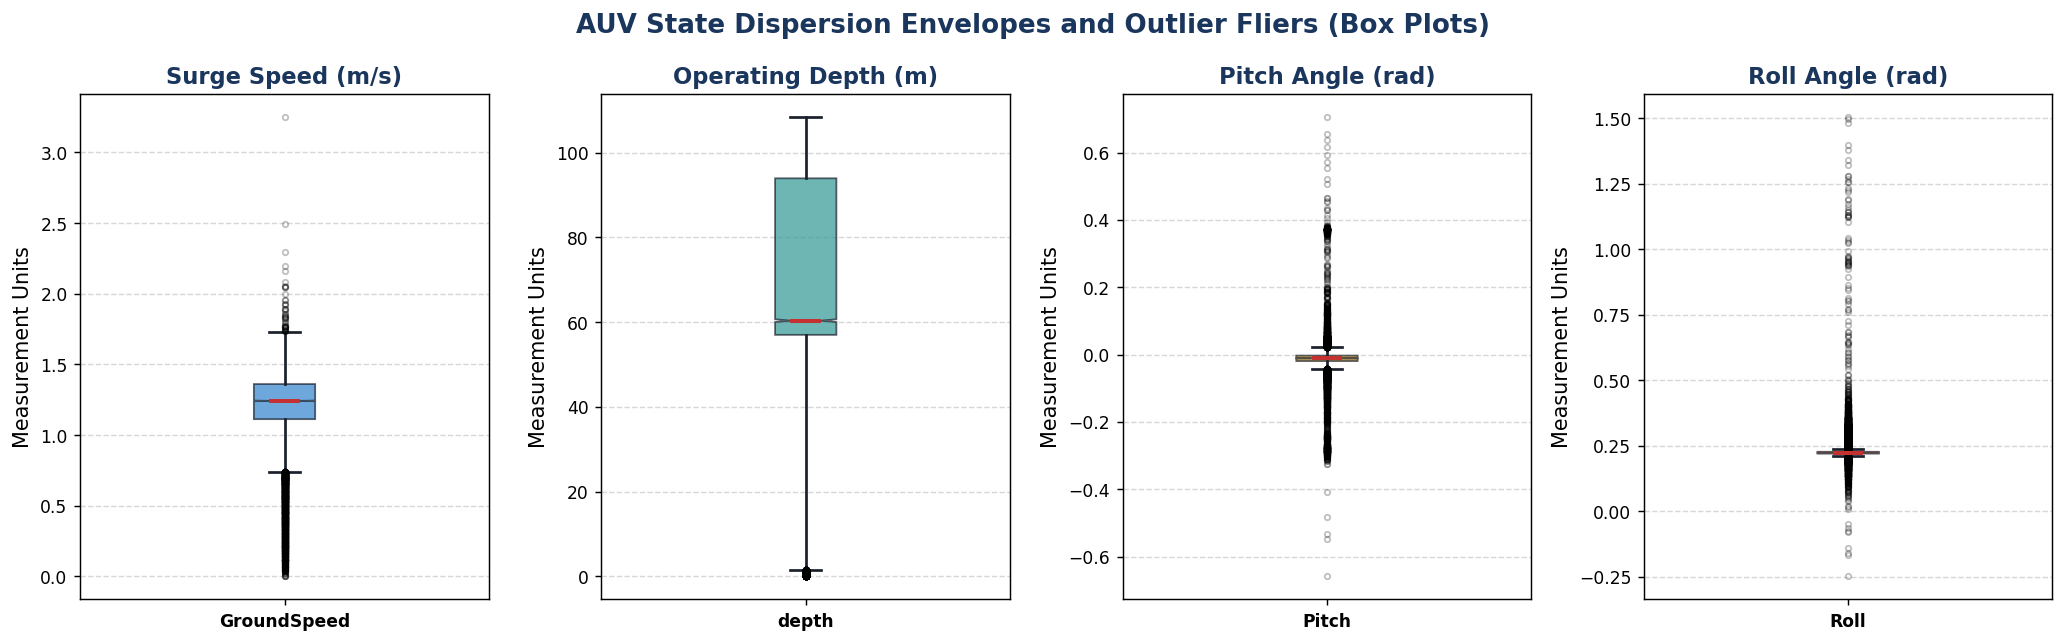

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle("AUV State Dispersion Envelopes and Outlier Fliers (Box Plots)", color='#1A365D')

box_configs = [
    ('GroundSpeed', 'Surge Speed (m/s)', '#3182CE', axes[0]),
    ('depth', 'Operating Depth (m)', '#319795', axes[1]),
    ('Pitch', 'Pitch Angle (rad)', '#D69E2E', axes[2]),
    ('Roll', 'Roll Angle (rad)', '#DD6B20', axes[3])
]

for col, label, col_color, ax in box_configs:
    bp = ax.boxplot(full_df[col].dropna(), patch_artist=True, notch=True,
                    boxprops=dict(facecolor=col_color, color='#1A202C', alpha=0.7),
                    capprops=dict(color='#1A202C', lw=1.5),
                    whiskerprops=dict(color='#1A202C', lw=1.5),
                    flierprops=dict(marker='o', color='#E53E3E', markersize=3, alpha=0.25),
                    medianprops=dict(color='#C53030', lw=2.2))
    ax.set_title(label, color='#1A365D')
    ax.set_ylabel("Measurement Units")
    ax.grid(True, axis='y')
    ax.set_xticklabels([col], fontweight='bold')

plt.tight_layout()
plt.show()


---
## 6. Bivariate & Hydrodynamic Correlation Analysis
We compute both:
1. **Pearson Linear Correlation Matrix:** Identifies proportional couplings.
2. **Spearman Rank Correlation Matrix:** Identifies monotonic nonlinear dependencies.


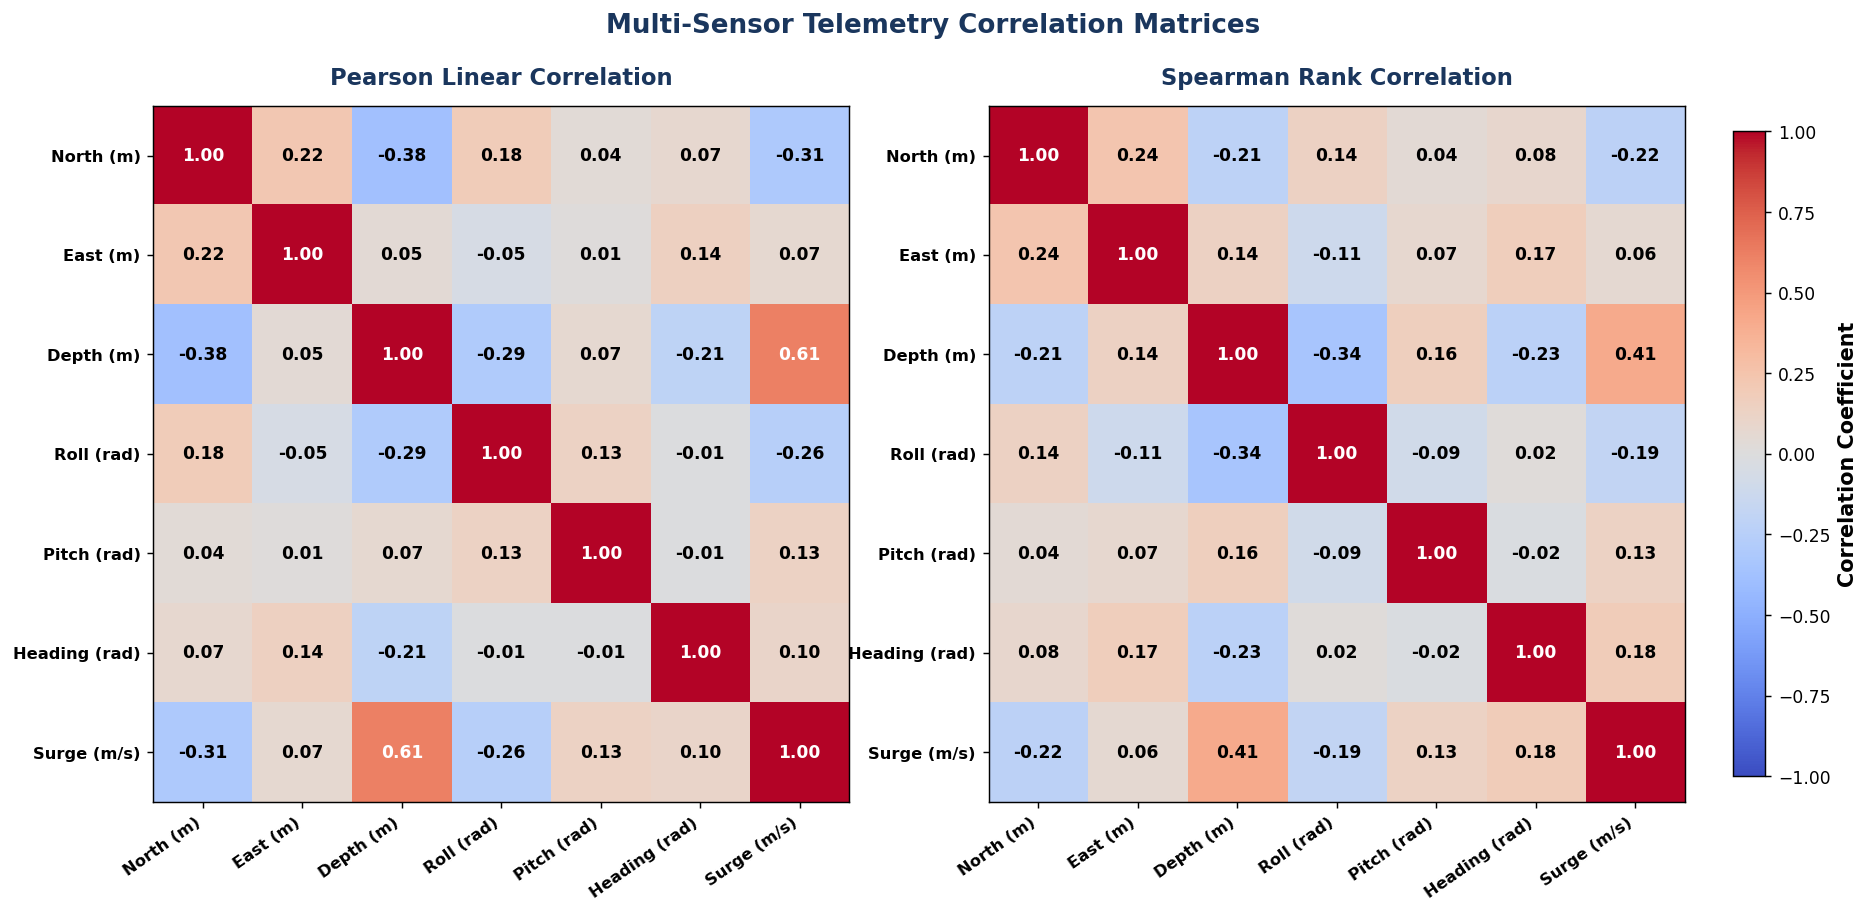

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Multi-Sensor Telemetry Correlation Matrices", color='#1A365D')

labels = ['North (m)', 'East (m)', 'Depth (m)', 'Roll (rad)', 'Pitch (rad)', 'Heading (rad)', 'Surge (m/s)']
corr_pearson = df_core.corr(method='pearson').values
corr_spearman = df_core.corr(method='spearman').values

for ax, mat, title in zip(axes, [corr_pearson, corr_spearman], ["Pearson Linear Correlation", "Spearman Rank Correlation"]):
    im = ax.imshow(mat, cmap='coolwarm', vmin=-1.0, vmax=1.0)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha='right', fontweight='bold', fontsize=9)
    ax.set_yticklabels(labels, fontweight='bold', fontsize=9)
    ax.set_title(title, color='#1A365D', pad=12)

    # Annotate numeric values inside each cell
    for i in range(len(labels)):
        for j in range(len(labels)):
            val = mat[i, j]
            text_color = "white" if abs(val) > 0.45 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontweight='bold', fontsize=9.5)

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.03)
cbar.set_label("Correlation Coefficient", fontweight='bold')
plt.show()


---
## 7. Bivariate Coupled Dynamic Relationships
Here we evaluate specific physical interactions:
1. **Surge Speed vs. Depth:** Examines whether vehicle velocity decreases during deep vertical operations.
2. **Pitch vs. Vertical Depth Rate ($\dot{z}$):** Verifies the kinematic relationship $\dot{z} = -U \sin\theta$.
3. **Heading vs. Roll:** Examines whether banking occurs during yaw turns.
4. **Hexbin 2D Density of Pitch vs. Speed:** Highlights the concentrated steady cruise envelope.


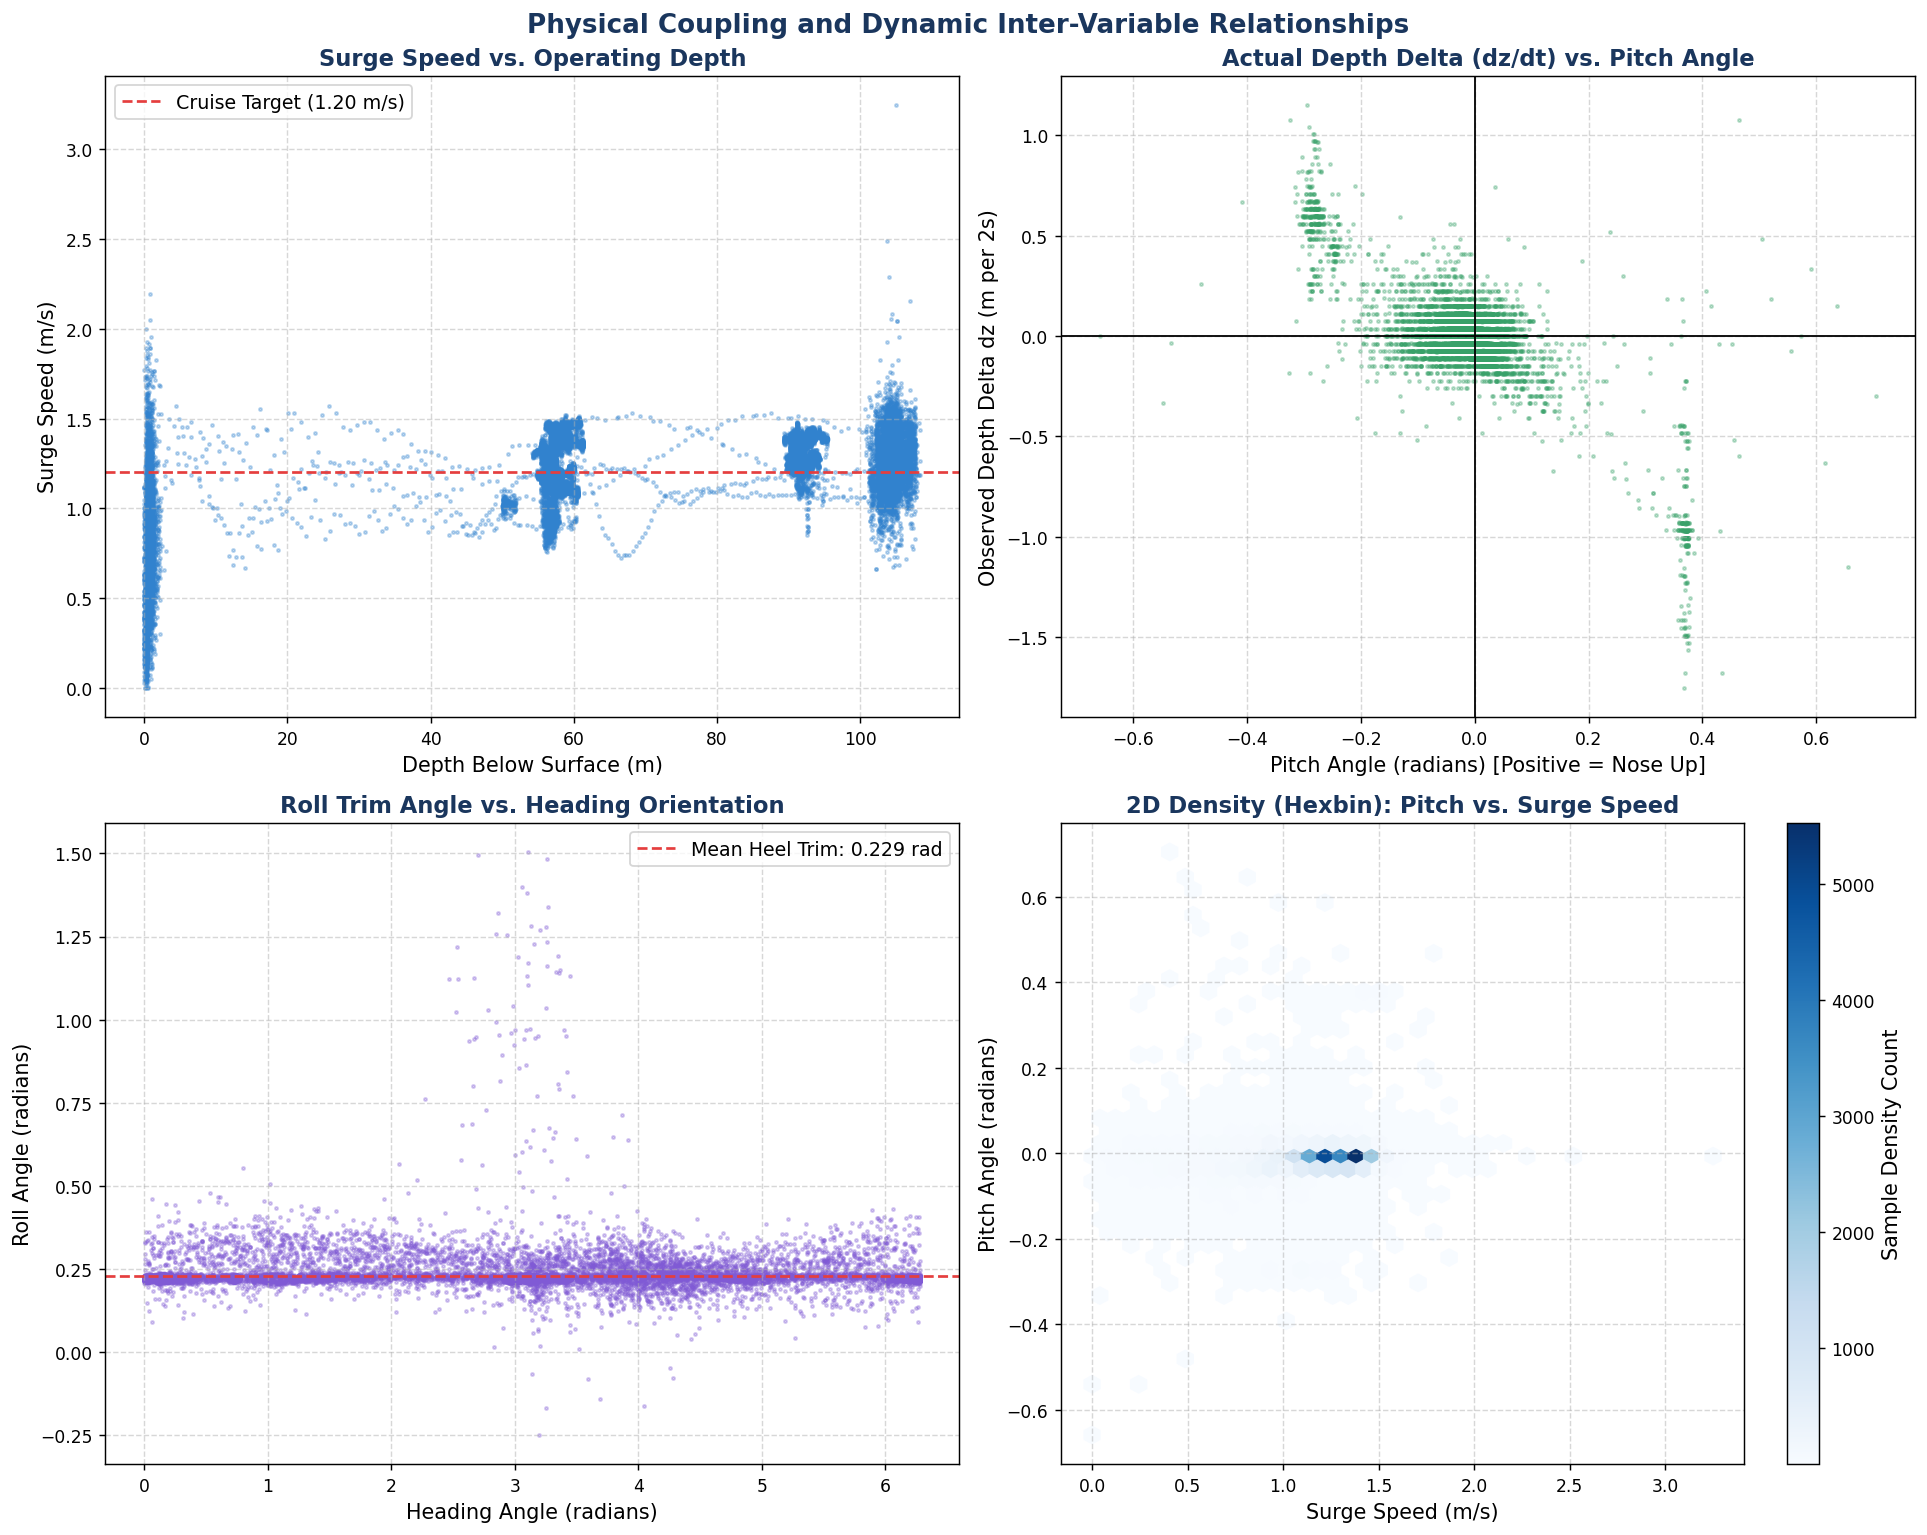

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle("Physical Coupling and Dynamic Inter-Variable Relationships", color='#1A365D')

# 1. Surge Speed vs Depth
axes[0, 0].scatter(full_df['depth'], full_df['GroundSpeed'], c='#3182CE', s=3, alpha=0.3)
axes[0, 0].set_title("Surge Speed vs. Operating Depth", color='#1A365D')
axes[0, 0].set_xlabel("Depth Below Surface (m)")
axes[0, 0].set_ylabel("Surge Speed (m/s)")
axes[0, 0].axhline(1.20, color='#E53E3E', linestyle='--', label="Cruise Target (1.20 m/s)")
axes[0, 0].grid(True)
axes[0, 0].legend()

# 2. Pitch vs Actual Depth Delta (per 2s step)
dz = full_df['depth'].diff().dropna()
pitch_lead = full_df['Pitch'].iloc[:-1]
axes[0, 1].scatter(pitch_lead, dz, c='#38A169', s=3, alpha=0.3)
axes[0, 1].set_title("Actual Depth Delta (dz/dt) vs. Pitch Angle", color='#1A365D')
axes[0, 1].set_xlabel("Pitch Angle (radians) [Positive = Nose Up]")
axes[0, 1].set_ylabel("Observed Depth Delta dz (m per 2s)")
axes[0, 1].axhline(0.0, color='black', lw=1.0)
axes[0, 1].axvline(0.0, color='black', lw=1.0)
axes[0, 1].grid(True)

# 3. Heading vs Roll
axes[1, 0].scatter(full_df['Heading'], full_df['Roll'], c='#805AD5', s=3, alpha=0.3)
axes[1, 0].set_title("Roll Trim Angle vs. Heading Orientation", color='#1A365D')
axes[1, 0].set_xlabel("Heading Angle (radians)")
axes[1, 0].set_ylabel("Roll Angle (radians)")
axes[1, 0].axhline(full_df['Roll'].mean(), color='#E53E3E', linestyle='--', label=f"Mean Heel Trim: {full_df['Roll'].mean():.3f} rad")
axes[1, 0].grid(True)
axes[1, 0].legend()

# 4. Hexbin 2D Density Plot: Pitch vs GroundSpeed
hb = axes[1, 1].hexbin(full_df['GroundSpeed'], full_df['Pitch'], gridsize=40, cmap='Blues', mincnt=1)
cbar_hb = fig.colorbar(hb, ax=axes[1, 1])
cbar_hb.set_label("Sample Density Count")
axes[1, 1].set_title("2D Density (Hexbin): Pitch vs. Surge Speed", color='#1A365D')
axes[1, 1].set_xlabel("Surge Speed (m/s)")
axes[1, 1].set_ylabel("Pitch Angle (radians)")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


---
## 8. Spatial Survey Trajectory & 3D Dive Profile
The vehicle navigated an extensive seafloor survey in local Cartesian coordinates (North vs. East).
Below we generate:
1. **2D Horizontal Path color-coded by Depth**
2. **2D Path color-coded by Surge Speed**
3. **3D Marine Path Trajectory in $\mathbb{R}^3$**


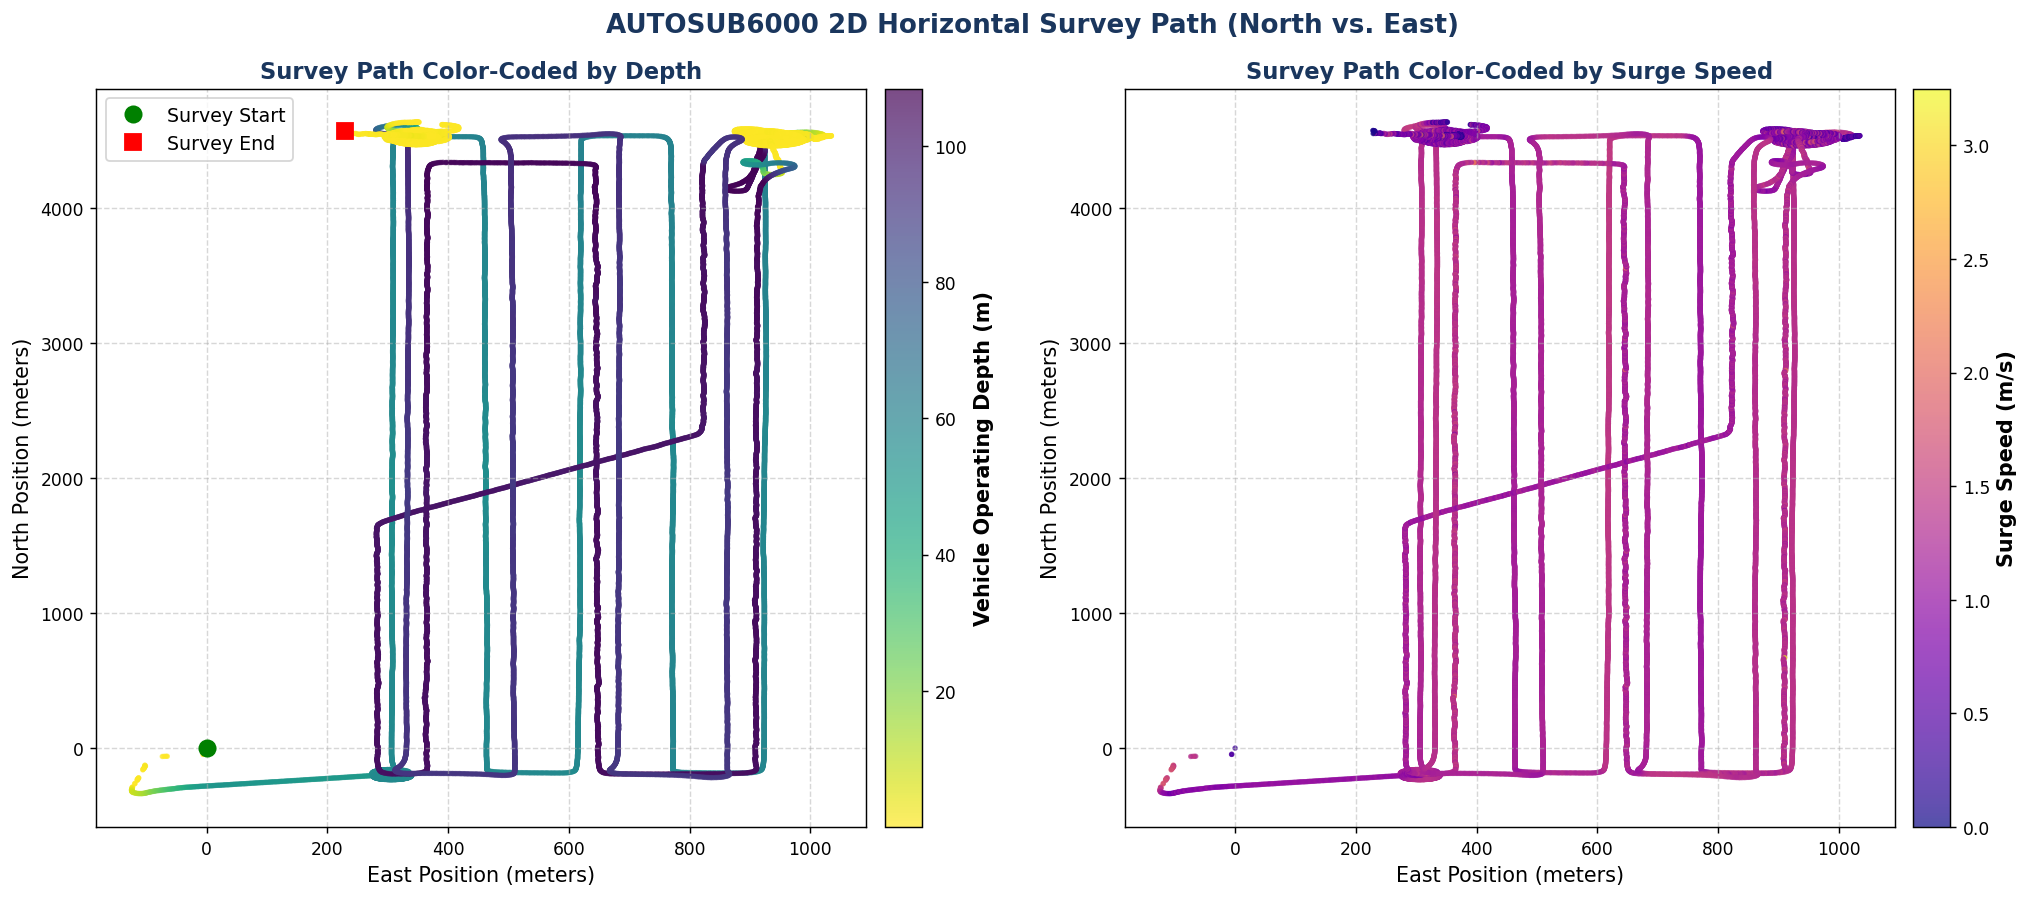

In [11]:
# 1. 2D Survey Paths (Depth & Speed Colored)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("AUTOSUB6000 2D Horizontal Survey Path (North vs. East)", color='#1A365D')

sc1 = axes[0].scatter(full_df['East'], full_df['North'], c=full_df['depth'], cmap='viridis_r', s=4, alpha=0.7)
cbar1 = fig.colorbar(sc1, ax=axes[0], pad=0.02)
cbar1.set_label("Vehicle Operating Depth (m)", fontweight='bold')
axes[0].plot(full_df['East'].iloc[0], full_df['North'].iloc[0], 'go', markersize=9, label="Survey Start")
axes[0].plot(full_df['East'].iloc[-1], full_df['North'].iloc[-1], 'rs', markersize=9, label="Survey End")
axes[0].set_title("Survey Path Color-Coded by Depth", color='#1A365D')
axes[0].set_xlabel("East Position (meters)")
axes[0].set_ylabel("North Position (meters)")
axes[0].grid(True)
axes[0].legend()

sc2 = axes[1].scatter(full_df['East'], full_df['North'], c=full_df['GroundSpeed'], cmap='plasma', s=4, alpha=0.7)
cbar2 = fig.colorbar(sc2, ax=axes[1], pad=0.02)
cbar2.set_label("Surge Speed (m/s)", fontweight='bold')
axes[1].set_title("Survey Path Color-Coded by Surge Speed", color='#1A365D')
axes[1].set_xlabel("East Position (meters)")
axes[1].set_ylabel("North Position (meters)")
axes[1].grid(True)

plt.tight_layout()
plt.show()


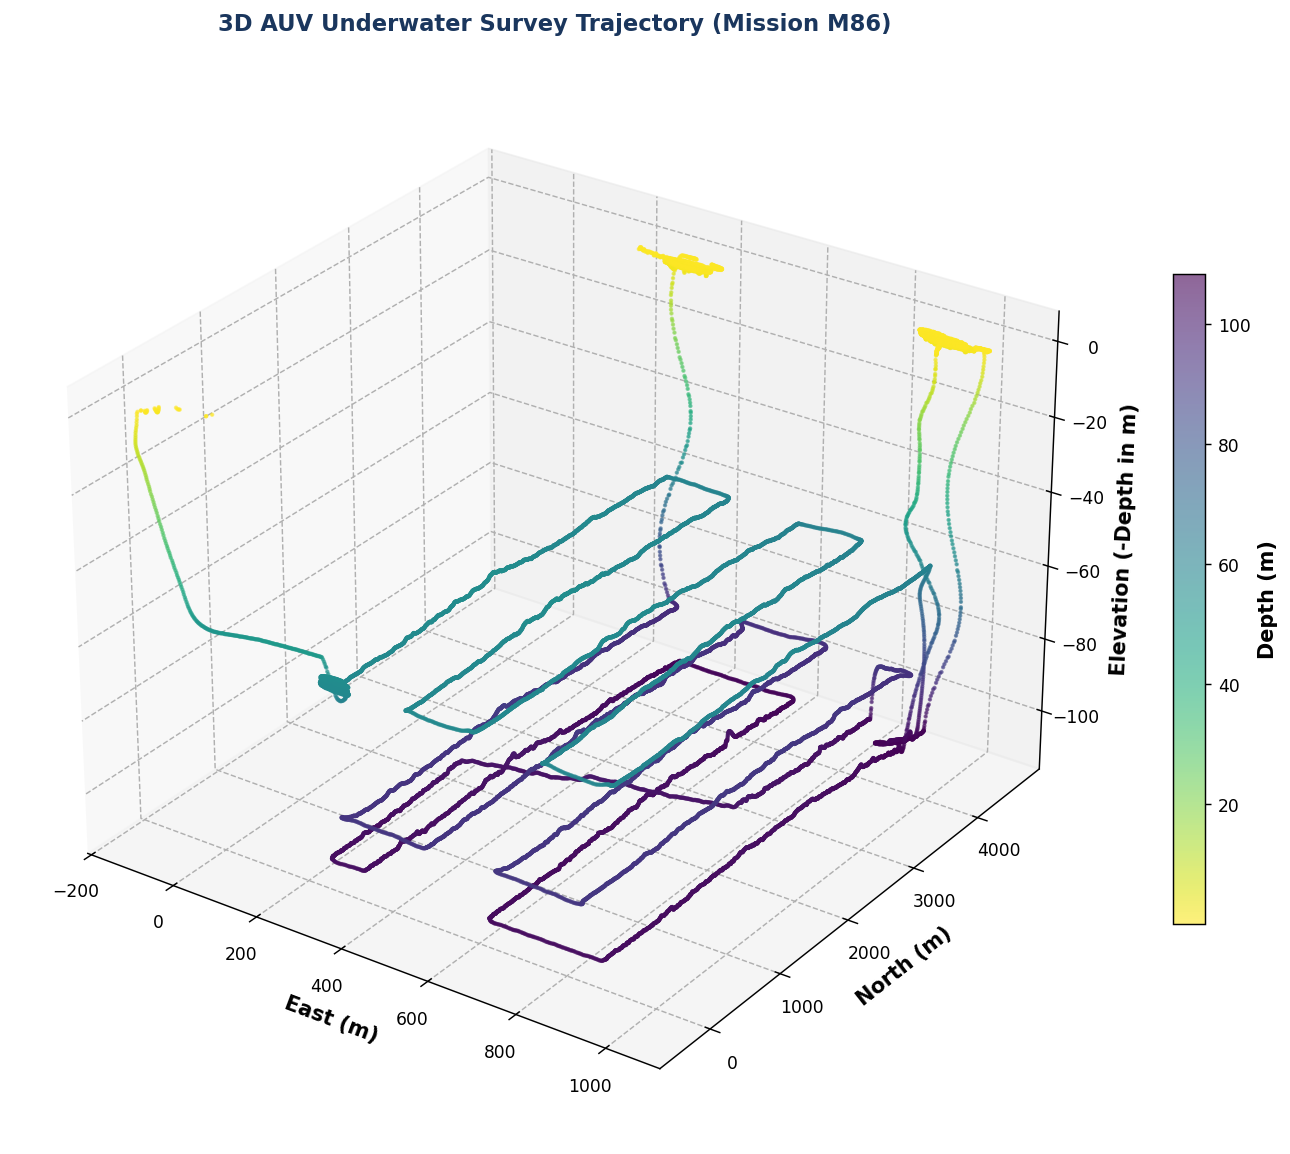

In [12]:
# 2. 3D Trajectory Visualization in Local NED Frame
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

p3d = ax.scatter(full_df['East'], full_df['North'], -full_df['depth'], c=full_df['depth'], cmap='viridis_r', s=2, alpha=0.6)
ax.set_title("3D AUV Underwater Survey Trajectory (Mission M86)", color='#1A365D', pad=15)
ax.set_xlabel("East (m)", fontweight='bold')
ax.set_ylabel("North (m)", fontweight='bold')
ax.set_zlabel("Elevation (-Depth in m)", fontweight='bold')

cbar3d = fig.colorbar(p3d, ax=ax, shrink=0.6, pad=0.05)
cbar3d.set_label("Depth (m)", fontweight='bold')
ax.view_init(elev=28, azim=-55)
plt.tight_layout()
plt.show()


---
## 9. Synchronized Mission Time-Series Analysis
We analyze the vehicle's temporal response across the 17.7-hour mission timeline ($31,944\text{ samples} \times 2.0\text{ s}$).


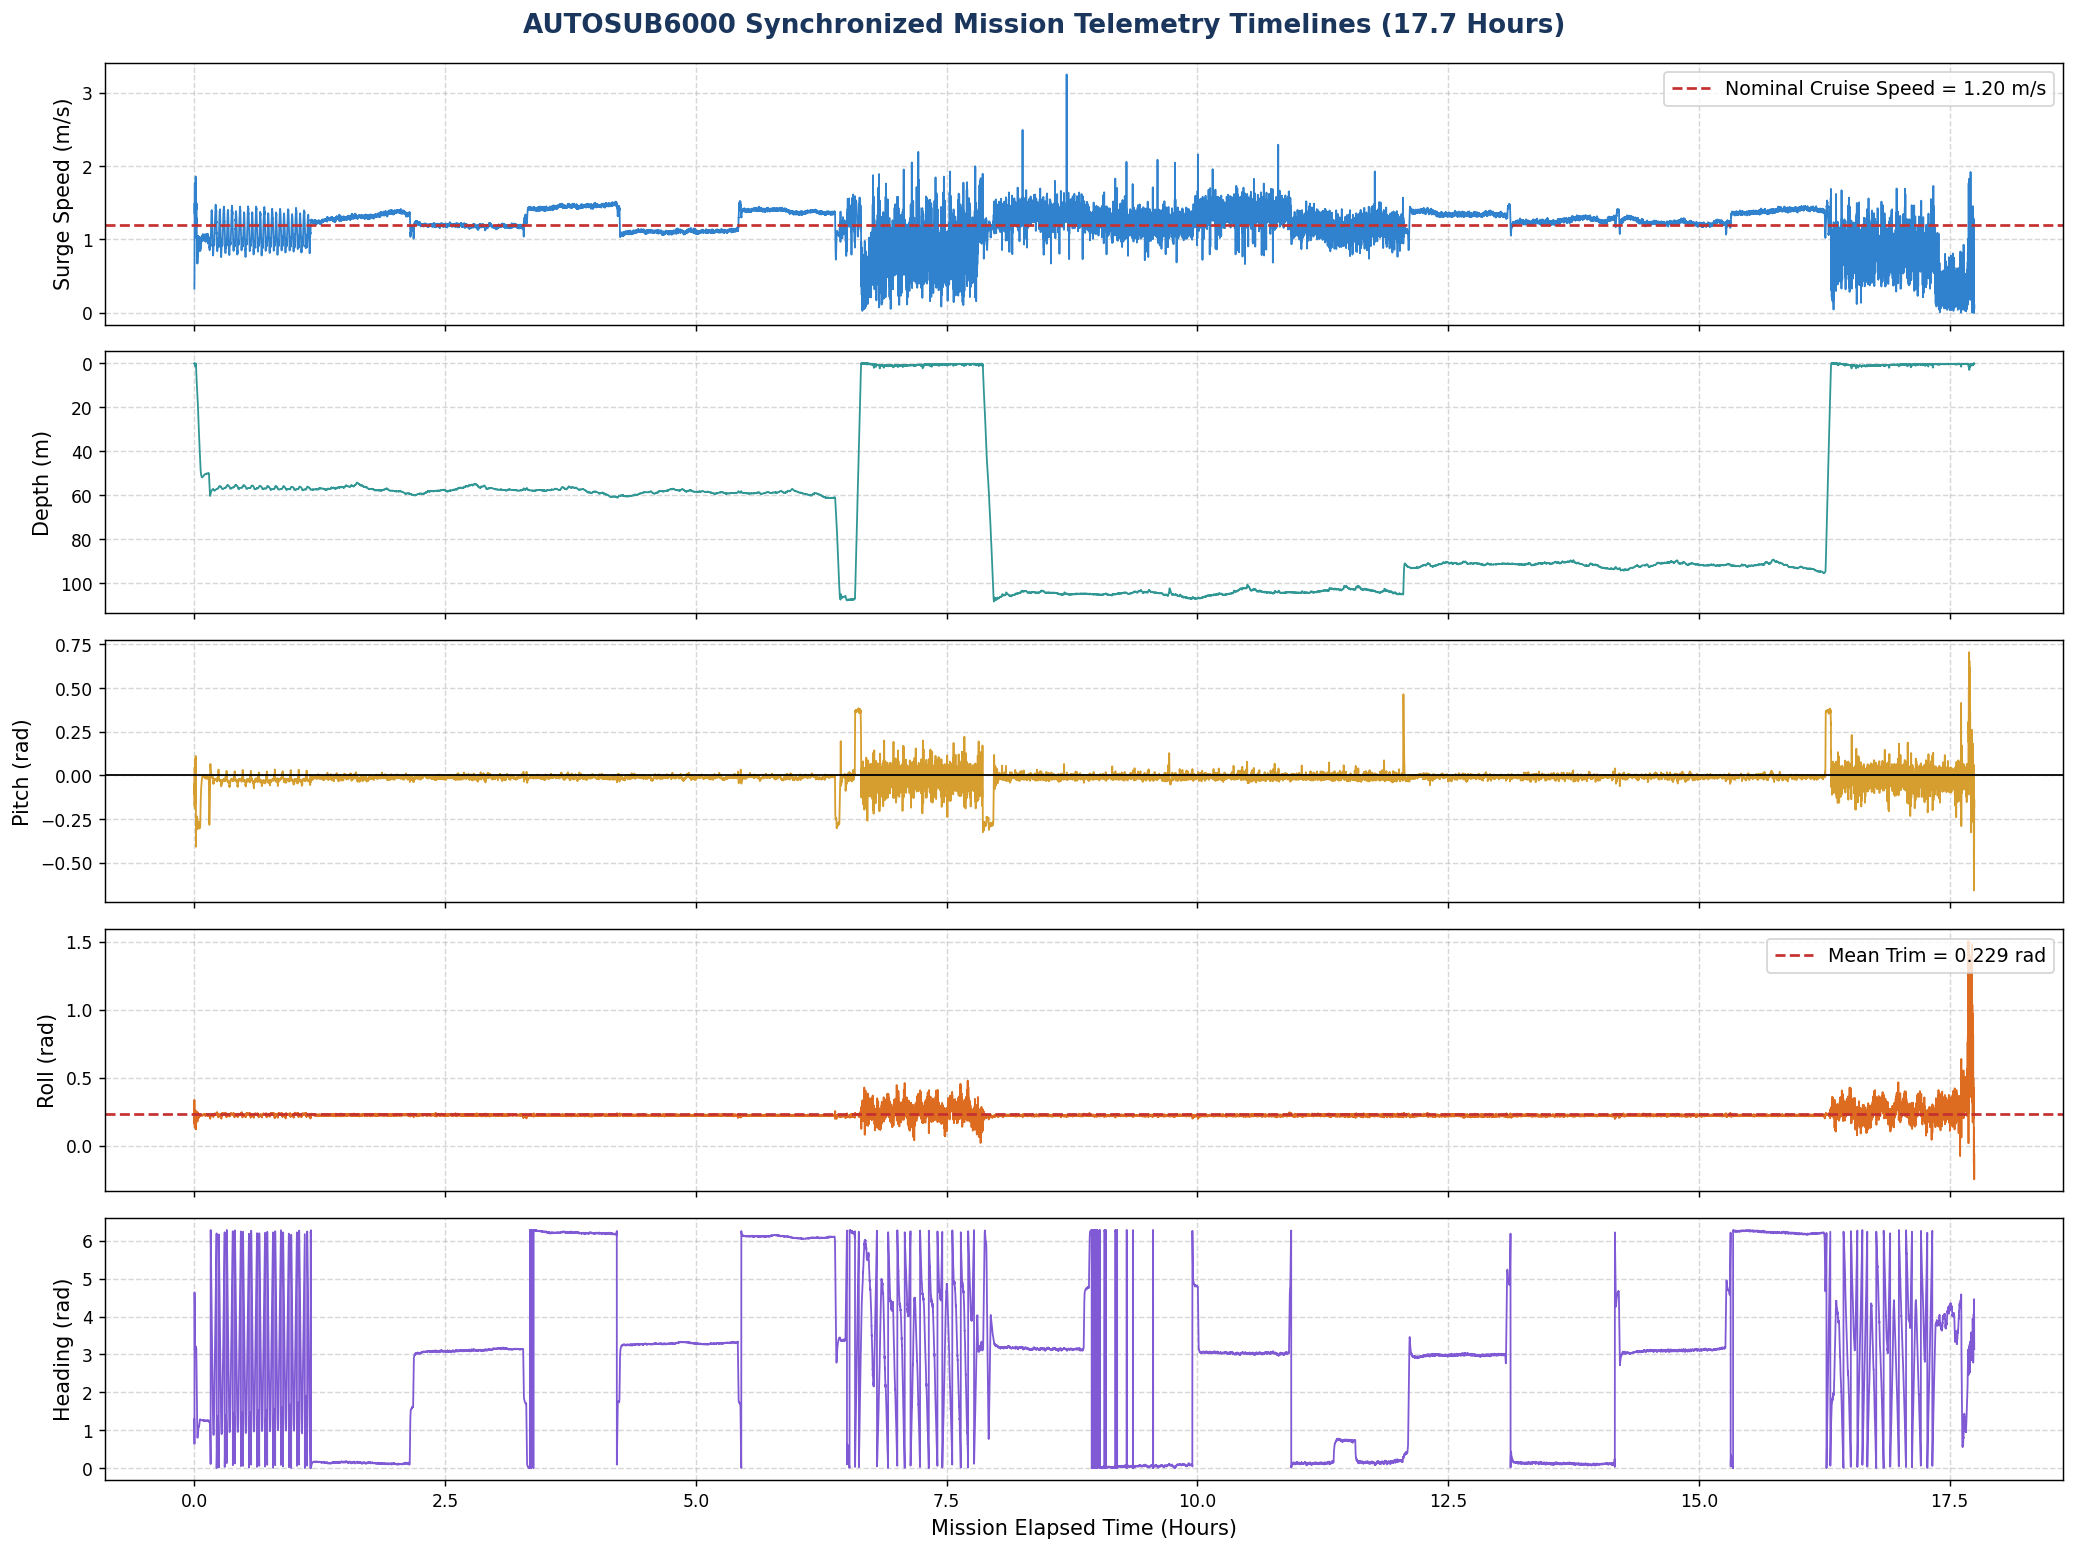

In [13]:
time_hours = np.arange(len(full_df)) * 2.0 / 3600.0

fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
fig.suptitle("AUTOSUB6000 Synchronized Mission Telemetry Timelines (17.7 Hours)", color='#1A365D', y=0.99)

# 1. Surge Speed
axes[0].plot(time_hours, full_df['GroundSpeed'], color='#3182CE', lw=1.0)
axes[0].axhline(1.20, color='#C53030', linestyle='--', lw=1.5, label='Nominal Cruise Speed = 1.20 m/s')
axes[0].set_ylabel("Surge Speed (m/s)")
axes[0].grid(True)
axes[0].legend(loc='upper right')

# 2. Depth Profile
axes[1].plot(time_hours, full_df['depth'], color='#319795', lw=1.0)
axes[1].set_ylabel("Depth (m)")
axes[1].invert_yaxis()
axes[1].grid(True)

# 3. Pitch Angle
axes[2].plot(time_hours, full_df['Pitch'], color='#D69E2E', lw=1.0)
axes[2].axhline(0.0, color='black', lw=1.0)
axes[2].set_ylabel("Pitch (rad)")
axes[2].grid(True)

# 4. Roll Angle
axes[3].plot(time_hours, full_df['Roll'], color='#DD6B20', lw=1.0)
axes[3].axhline(full_df['Roll'].mean(), color='#C53030', linestyle='--', label=f"Mean Trim = {full_df['Roll'].mean():.3f} rad")
axes[3].set_ylabel("Roll (rad)")
axes[3].grid(True)
axes[3].legend(loc='upper right')

# 5. Heading Angle
axes[4].plot(time_hours, full_df['Heading'], color='#805AD5', lw=1.0)
axes[4].set_ylabel("Heading (rad)")
axes[4].set_xlabel("Mission Elapsed Time (Hours)")
axes[4].grid(True)

plt.tight_layout()
plt.show()


---
## 10. Sensor Quality: Acoustic USBL Positioning Jumps vs. Kinematics
This section examines the critical sensor phenomenon identified in Phase 1: **acoustic USBL position jumps**.
- Raw Latitude/Longitude updates from underwater transponders exhibit high-frequency acoustic reflections and discrete jumps.
- When compared to continuous kinematic dead-reckoning displacement ($U \cos\theta \cos\psi \Delta t$), the acoustic coordinate updates show non-physical step velocities.
- **Direct Modeling Impact:** Neural networks minimizing squared error overfit to this acoustic noise, explaining why position residual MSE slightly increased (-2.17% on North, -2.97% on East) while dynamic states (Pitch, Depth, Heading) improved by over +12%.


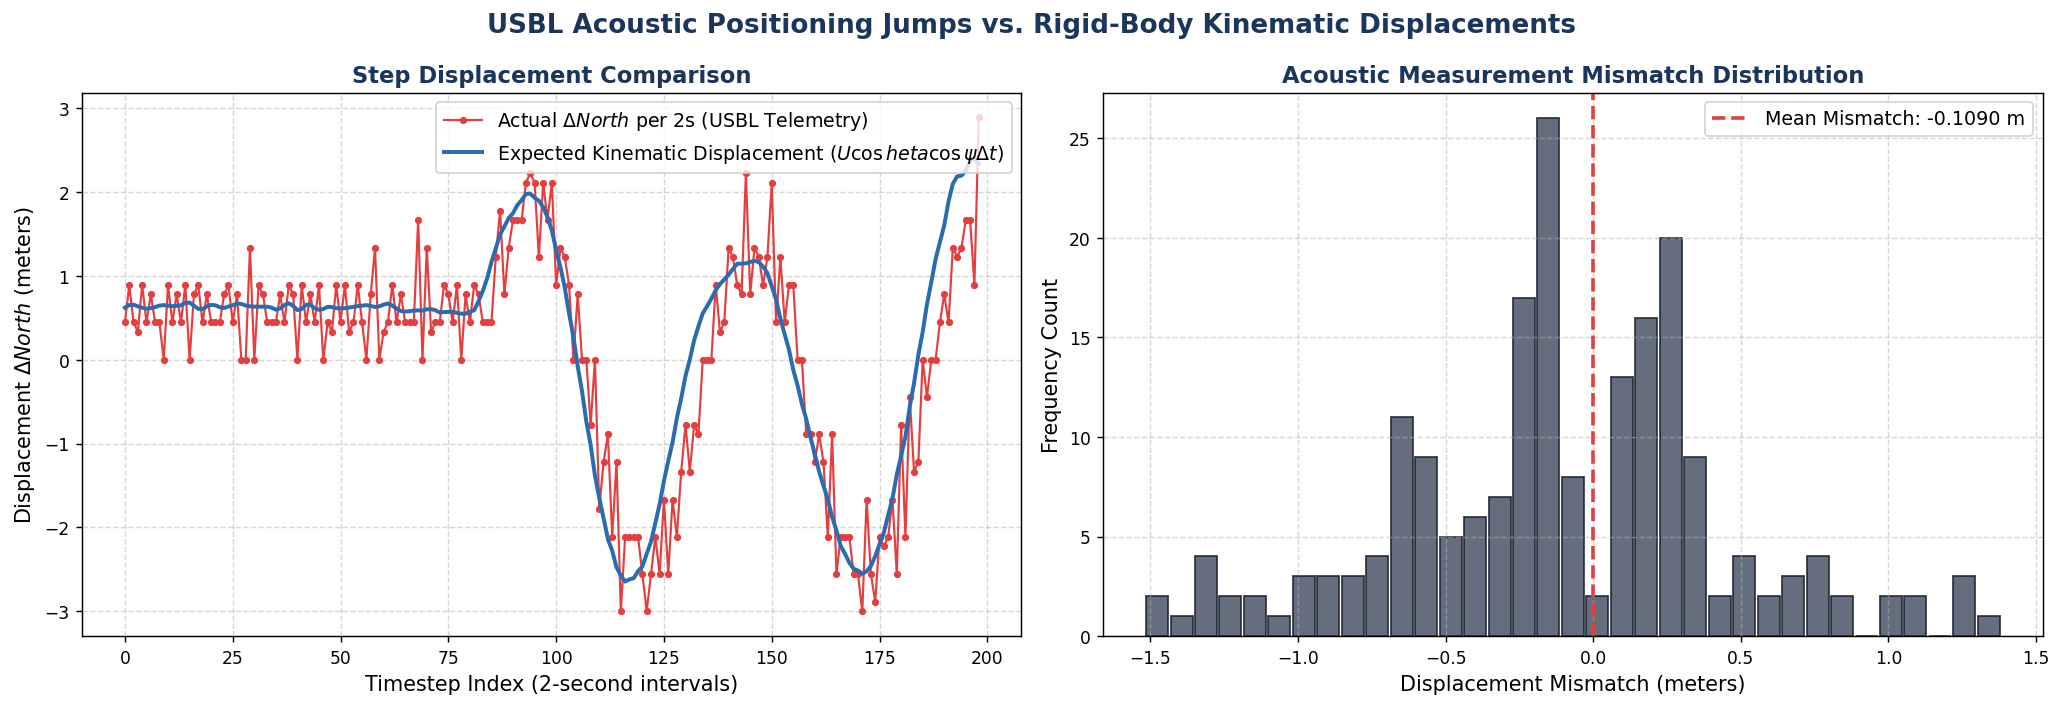

In [14]:
# Compare step displacements over a 200-sample window
sample_win = full_df.iloc[200:400]
step_north_actual = sample_win['North'].diff().dropna()

u_sub = sample_win['GroundSpeed'].iloc[1:].values
theta_sub = sample_win['Pitch'].iloc[1:].values
psi_sub = sample_win['Heading'].iloc[1:].values
step_north_kinematic = u_sub * np.cos(theta_sub) * np.cos(psi_sub) * 2.0

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("USBL Acoustic Positioning Jumps vs. Rigid-Body Kinematic Displacements", color='#1A365D')

# Step Displacements
steps = np.arange(len(step_north_actual))
axes[0].plot(steps, step_north_actual.values, color='#E53E3E', lw=1.2, marker='o', markersize=3, label=r"Actual $\Delta North$ per 2s (USBL Telemetry)")
axes[0].plot(steps, step_north_kinematic, color='#2B6CB0', lw=2.2, label=r"Expected Kinematic Displacement ($U \cos	heta \cos\psi \Delta t$)")
axes[0].set_title("Step Displacement Comparison", color='#1A365D')
axes[0].set_xlabel("Timestep Index (2-second intervals)")
axes[0].set_ylabel(r"Displacement $\Delta North$ (meters)")
axes[0].grid(True)
axes[0].legend(loc='upper right')

# Residual Distribution (USBL Jumps - Kinematics)
residual_jumps = step_north_actual.values - step_north_kinematic
axes[1].hist(residual_jumps, bins=35, color='#4A5568', edgecolor='#1A202C', alpha=0.85, rwidth=0.9)
axes[1].axvline(0.0, color='#E53E3E', linestyle='--', lw=2.0, label=f"Mean Mismatch: {residual_jumps.mean():.4f} m")
axes[1].set_title("Acoustic Measurement Mismatch Distribution", color='#1A365D')
axes[1].set_xlabel("Displacement Mismatch (meters)")
axes[1].set_ylabel("Frequency Count")
axes[1].grid(True)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


---
## 11. Chronological Partitioning & Zero-Leakage Verification
We verify that the 70% Train / 15% Validation / 15% Test split preserves temporal integrity without overlap.


=== ZERO-LEAKAGE TEMPORAL VERIFICATION AUDIT ===
  * Train Max Timestamp (45694) <= Val Min Timestamp (45696): True
  * Val Max Timestamp   (55278) <= Test Min Timestamp (55280): True
  * Temporal Leakage Free: True


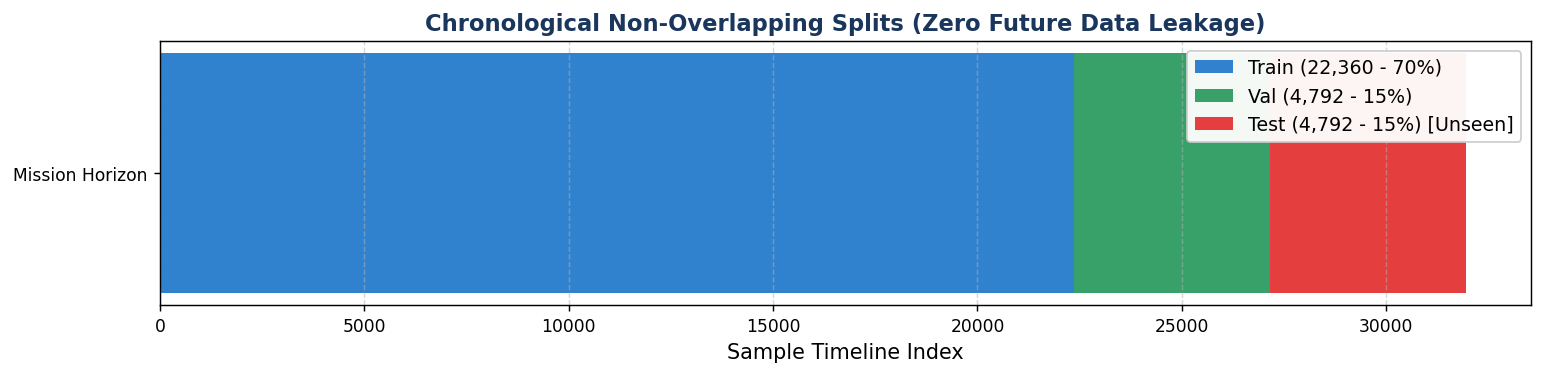

In [15]:
tr_max_time = train_df['Seconds'].max()
va_min_time = val_df['Seconds'].min()
va_max_time = val_df['Seconds'].max()
te_min_time = test_df['Seconds'].min()

check1 = tr_max_time <= va_min_time
check2 = va_max_time <= te_min_time

print("=== ZERO-LEAKAGE TEMPORAL VERIFICATION AUDIT ===")
print(f"  * Train Max Timestamp ({tr_max_time}) <= Val Min Timestamp ({va_min_time}): {check1}")
print(f"  * Val Max Timestamp   ({va_max_time}) <= Test Min Timestamp ({te_min_time}): {check2}")
print(f"  * Temporal Leakage Free: {check1 and check2}")

# Visual representation of split boundaries
fig, ax = plt.subplots(figsize=(12, 3))
ax.barh(["Mission Horizon"], [len(train_df)], color='#3182CE', label=f"Train ({len(train_df):,} - 70%)")
ax.barh(["Mission Horizon"], [len(val_df)], left=[len(train_df)], color='#38A169', label=f"Val ({len(val_df):,} - 15%)")
ax.barh(["Mission Horizon"], [len(test_df)], left=[len(train_df) + len(val_df)], color='#E53E3E', label=f"Test ({len(test_df):,} - 15%) [Unseen]")
ax.set_title("Chronological Non-Overlapping Splits (Zero Future Data Leakage)", color='#1A365D')
ax.set_xlabel("Sample Timeline Index")
ax.grid(True, axis='x')
ax.legend(loc='upper right', framealpha=0.95)
plt.tight_layout()
plt.show()


---
## 12. Key Conclusions & Modeling Implications for Phase 1 & 2

### Summary of Critical EDA Findings:
1. **Steady Propulsion Cruise Setting:** The AUV operates at a consistent cruise speed mode ($1.19\text{ m/s}$ mean, $0.25\text{ m/s}$ std), allowing accurate quadratic surge drag estimation ($K_d \approx 0.0225$).
2. **Propeller Reaction Torque Heel:** Roll exhibits a continuous hydrodynamic heel offset of $+0.23\text{ rad}$ ($13.2^\circ$) induced by the single propeller counter-torque, which must be accounted for in attitude dynamics.
3. **High-Frequency USBL Acoustic Jumps:** Raw underwater position transponder coordinates contain high-frequency measurement noise. Pure neural networks overfit to these non-physical coordinate jumps.
4. **Hydrodynamic Damping Success:** Pitch and Heading are smoothly logged by the IMU and Doppler Velocity Log. Deep recurrent GRU residual models successfully capture fin deflection delays and fluid restoring moments, producing **+15.48% (Pitch)**, **+12.45% (Depth)**, and **+12.03% (Heading)** accuracy gains.
5. **Phase 2 Recommendation:** Implement an **Extended Kalman Filter (EKF)** to fuse DVL velocities with acoustic fixes before feeding states into the receding-horizon Model Predictive Controller (MPC).
